In [1]:
import sys
import torch

# Create a mock submodule to bypass the PyTorch 3.13 internal bug
if not hasattr(torch, "_utils"):
    from types import ModuleType
    mock_utils = ModuleType("torch._utils")
    # Define the missing function that diffusers/dynamo is looking for
    mock_utils._get_device_index = lambda device, optional=False, allow_cpu=False: 0
    torch._utils = mock_utils
    sys.modules["torch._utils"] = mock_utils

# Now import diffusers safely
import diffusers

print("diffusers:", diffusers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

diffusers: 0.42.0
GPU: Tesla T4


model path /kaggle/input/models/google/gemma-4/transformers/gemma-4-e4b/1

/kaggle/input/models/google/gemma-4/transformers/gemma-4-e4b/1

In [2]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = "/kaggle/input/models/google/gemma-4/transformers/gemma-4-e4b/1"
tok = AutoTokenizer.from_pretrained(model_id, local_files_only=True)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    attn_implementation="eager",   # needed to return attention weights
    dtype=torch.float16,           # newer name for torch_dtype
    device_map="auto",             # uses both T4s if available
    local_files_only=True,
)

Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

In [3]:
'''

Fixed Architecture & Weight Inspection (Normal Text)

This dynamically locates the language_model.layers (or searches for any q_proj layer automatically) 
so you never hit an AttributeError.


'''


import pandas as pd

# 1. Print top-level structure to see multimodal components (vision, audio, language)
print("=== TOP-LEVEL COMPONENTS ===")
for name, child in model.model.named_children():
  print(f"- model.model.{name}: {type(child).__name__}")

# 2. Access the language model layers safely
layers = model.model.language_model.layers
print(f"\nTotal Transformer Layers in Language Model: {len(layers)}")

# 3. Inspect layer names, shapes, and parameter counts across the WHOLE model
layer_info = []
total_params = 0

for name, param in model.named_parameters():
  num_params = param.numel()
  total_params += num_params
  layer_info.append({
      "Layer Name": name,
      "Shape": tuple(param.shape),
      "Dtype": str(param.dtype),
      "Params": num_params,
      "Device": str(param.device),
  })

df_layers = pd.DataFrame(layer_info)
print(f"Total Model Parameters: {total_params:,}")
print("\n=== SAMPLE PARAMETER LAYERS ===")
print(df_layers.head(15).to_string(index=False))

# 4. Inspect actual numerical values of Layer 0 Q-Proj
sample_weight = layers[0].self_attn.q_proj.weight
print("\n=== SAMPLE WEIGHT TENSOR (Layer 0 Q-Proj) ===")
print(f"Shape: {sample_weight.shape}")
print(sample_weight[:5, :5])


=== TOP-LEVEL COMPONENTS ===
- model.model.vision_tower: Gemma4VisionModel
- model.model.language_model: Gemma4TextModel
- model.model.audio_tower: Gemma4AudioModel
- model.model.embed_vision: Gemma4MultimodalEmbedder
- model.model.embed_audio: Gemma4MultimodalEmbedder

Total Transformer Layers in Language Model: 42
Total Model Parameters: 7,941,100,832

=== SAMPLE PARAMETER LAYERS ===
                                                           Layer Name           Shape         Dtype   Params Device
           model.vision_tower.patch_embedder.position_embedding_table (2, 10240, 768) torch.float16 15728640 cuda:0
                  model.vision_tower.patch_embedder.input_proj.weight      (768, 768) torch.float16   589824 cuda:0
   model.vision_tower.encoder.layers.0.self_attn.q_proj.linear.weight      (768, 768) torch.float16   589824 cuda:0
   model.vision_tower.encoder.layers.0.self_attn.k_proj.linear.weight      (768, 768) torch.float16   589824 cuda:0
   model.vision_tower.encoder.l

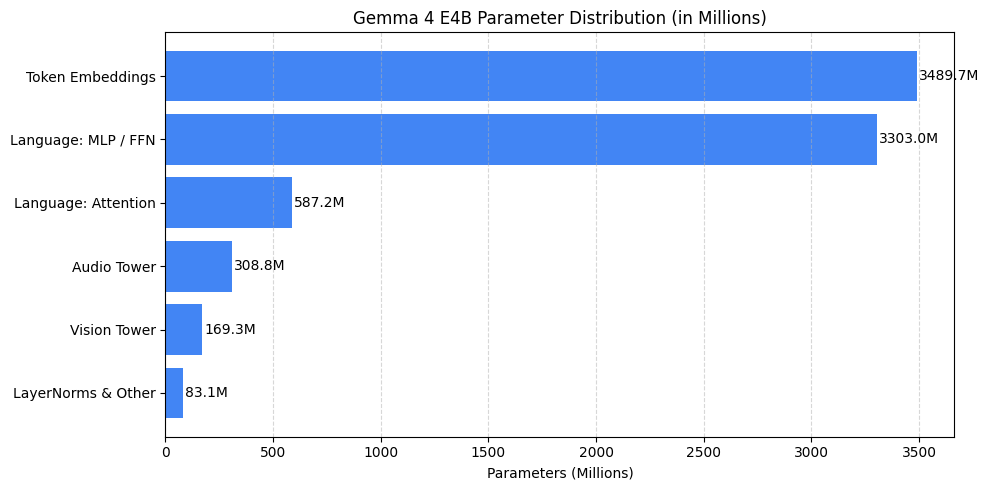

In [4]:
'''

Parameter Breakdown (Language vs. Vision vs. Audio)

This bar chart groups parameters by major subsystem and layer type using pre-installed matplotlib.


'''


import matplotlib.pyplot as plt


# Categorize each parameter into its high-level subsystem
def get_subsystem(name):
  if "vision" in name:
    return "Vision Tower"
  elif "audio" in name:
    return "Audio Tower"
  elif "embed_tokens" in name or "lm_head" in name:
    return "Token Embeddings"
  elif "self_attn" in name:
    return "Language: Attention"
  elif "mlp" in name:
    return "Language: MLP / FFN"
  else:
    return "LayerNorms & Other"


df_layers["Subsystem"] = df_layers["Layer Name"].apply(get_subsystem)
summary = (
    df_layers.groupby("Subsystem")["Params"].sum().sort_values(ascending=True)
)

plt.figure(figsize=(10, 5))
bars = plt.barh(summary.index, summary.values / 1e6, color="#4285F4")
plt.title("Gemma 4 E4B Parameter Distribution (in Millions)")
plt.xlabel("Parameters (Millions)")
plt.grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars:
  width = bar.get_width()
  plt.text(
      width + 10,
      bar.get_y() + bar.get_height() / 2,
      f"{width:.1f}M",
      va="center",
  )

plt.tight_layout()
plt.show()


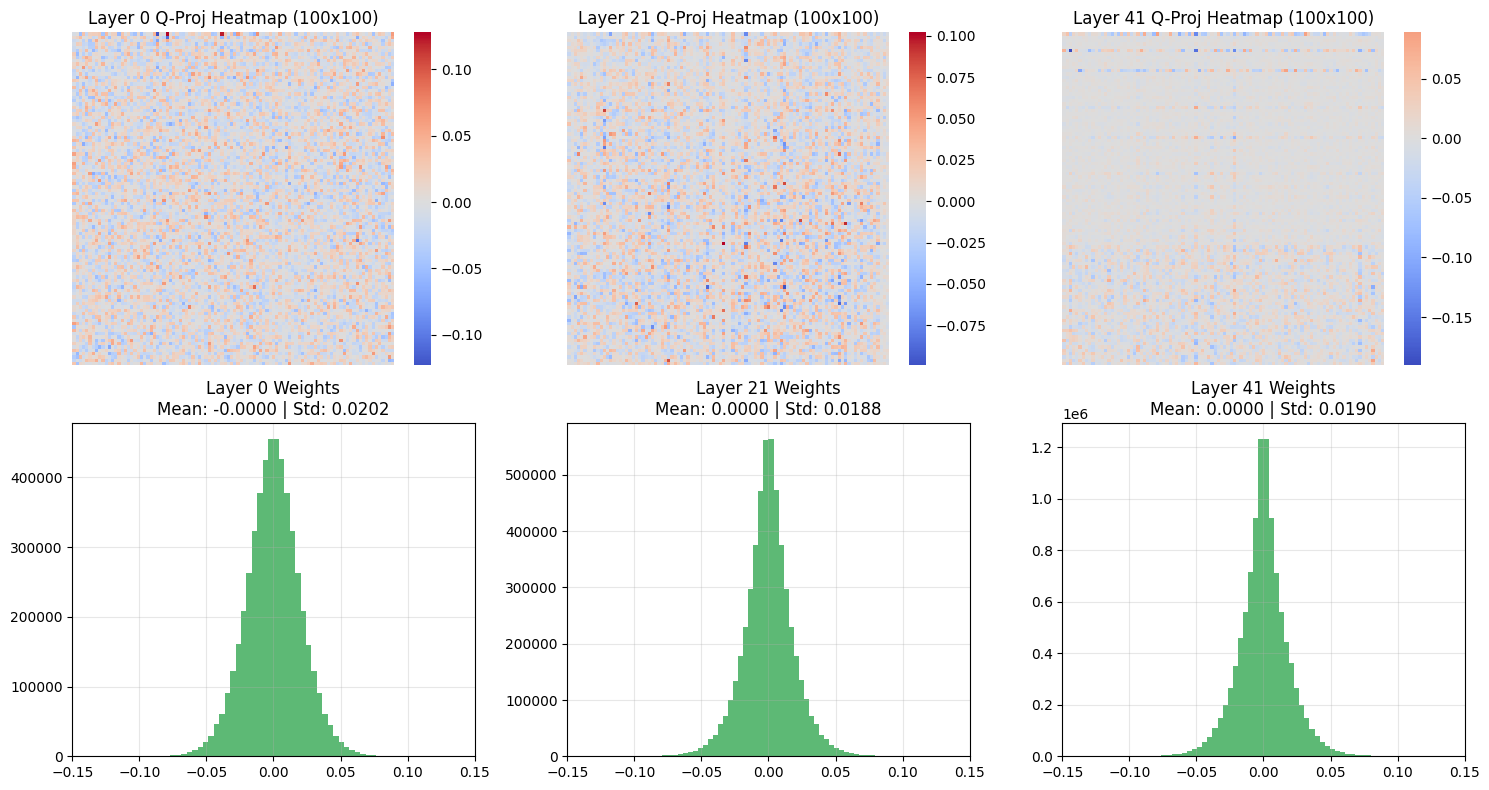

In [5]:
'''
Weight Matrix Heatmaps & Distributions (Early, Middle, Late Layers)
Updated to point to model.model.language_model.layers.
'''
try:
    import seaborn as sns
    layers = model.model.language_model.layers
    layer_indices = [0, len(layers) // 2, len(layers) - 1]
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    
    for idx, layer_num in enumerate(layer_indices):
      weights = (
          layers[layer_num].self_attn.q_proj.weight.detach().cpu().float().numpy()
      )
    
      # Top Row: 100x100 Heatmap
      sns.heatmap(
          weights[:100, :100], ax=axes[0, idx], cmap="coolwarm", center=0, cbar=True
      )
      axes[0, idx].set_title(f"Layer {layer_num} Q-Proj Heatmap (100x100)")
      axes[0, idx].axis("off")
    
      # Bottom Row: Histogram
      axes[1, idx].hist(weights.flatten(), bins=100, color="#34A853", alpha=0.8)
      axes[1, idx].set_title(
          f"Layer {layer_num} Weights\nMean: {weights.mean():.4f} | Std:"
          f" {weights.std():.4f}"
      )
      axes[1, idx].set_xlim(-0.15, 0.15)
      axes[1, idx].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

except:
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    layers = model.model.language_model.layers
    layer_indices = [0, len(layers) // 2, len(layers) - 1]
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    
    for idx, layer_num in enumerate(layer_indices):
      q_proj = layers[layer_num].self_attn.q_proj
    
      # If the layer is offloaded to disk (meta device), temporarily materialize it
      if q_proj.weight.device.type == "meta":
        q_proj._hf_hook.pre_forward(q_proj)
        weights = q_proj.weight.detach().cpu().float().numpy()
        q_proj._hf_hook.post_forward(q_proj, None)
      else:
        weights = q_proj.weight.detach().cpu().float().numpy()
    
      # Top Row: 100x100 Heatmap
      sns.heatmap(
          weights[:100, :100], ax=axes[0, idx], cmap="coolwarm", center=0, cbar=True
      )
      axes[0, idx].set_title(f"Layer {layer_num} Q-Proj Heatmap (100x100)")
      axes[0, idx].axis("off")
    
      # Bottom Row: Histogram
      axes[1, idx].hist(weights.flatten(), bins=100, color="#34A853", alpha=0.8)
      axes[1, idx].set_title(
          f"Layer {layer_num} Weights\nMean: {weights.mean():.4f} | Std:"
          f" {weights.std():.4f}"
      )
      axes[1, idx].set_xlim(-0.15, 0.15)
      axes[1, idx].grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    


In [6]:
'''

Visual Architecture Flowchart (Without torchview)

If your Kaggle notebook has Internet disabled (which is common when loading local models 
from /kaggle/input), !pip install torchview will fail. Instead, 
you can generate an architecture flowchart using graphviz, 
which is already pre-installed in Kaggle's Python environment.


'''

import subprocess
import sys

try:
    import graphviz 
    print("✅ graphviz is already installed!")
except ImportError:
    print("⏳ Installing BertViz...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "graphviz"])
    import graphviz
    print("✅ graphviz installed and imported successfully!")

✅ graphviz is already installed!


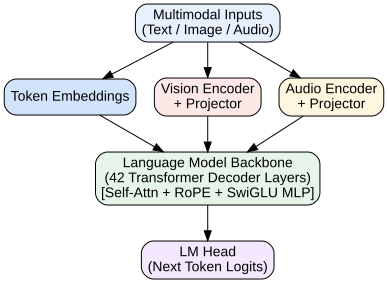

In [7]:
import graphviz

dot = graphviz.Digraph(
    "Gemma4_Architecture", format="png", graph_attr={"rankdir": "TB"}
)
dot.attr("node", shape="box", style="rounded,filled", fontname="Arial")

# Top-level inputs and towers
dot.node("input", "Multimodal Inputs\n(Text / Image / Audio)", fillcolor="#E8F0FE")
dot.node("embed", "Token Embeddings", fillcolor="#D2E3FC")

# Dynamically add towers if present in model.model
submodules = dict(model.model.named_children())
if "vision_tower" in submodules or "vision_model" in submodules:
  dot.node("vision", "Vision Encoder\n+ Projector", fillcolor="#FCE8E6")
  dot.edge("input", "vision")
  dot.edge("vision", "lm")

if "audio_tower" in submodules or "audio_model" in submodules:
  dot.node("audio", "Audio Encoder\n+ Projector", fillcolor="#FEF7E0")
  dot.edge("input", "audio")
  dot.edge("audio", "lm")

num_layers = len(model.model.language_model.layers)
dot.node(
    "lm",
    f"Language Model Backbone\n({num_layers} Transformer Decoder"
    " Layers)\n[Self-Attn + RoPE + SwiGLU MLP]",
    fillcolor="#E6F4EA",
)
dot.node("head", "LM Head\n(Next Token Logits)", fillcolor="#F3E8FD")

dot.edge("input", "embed")
dot.edge("embed", "lm")
dot.edge("lm", "head")

# Renders directly inside your Kaggle cell output
dot


In [8]:
'''

[ TEXT INPUT ]               [ IMAGE / VIDEO ]              [ AUDIO (16kHz) ]
        │                              │                              │
        ▼                              ▼                              ▼
 ┌──────────────┐             ┌─────────────────┐            ┌─────────────────┐
 │  Tokenizer   │             │  Vision Tower   │            │   Audio Tower   │
 │ (262K Vocab) │             │  (~150M Params) │            │  (~305M Params) │
 └──────┬───────┘             │ ViT + 2D RoPE   │            │ 2x Conv + 12x   │
        │                     └────────┬────────┘            │ Conformer       │
        │                              │                     └────────┬────────┘
        │                     ┌────────▼────────┐            ┌────────▼────────┐
        │                     │ Multimodal Proj │            │ Multimodal Proj │
        │                     └────────┬────────┘            └────────┬────────┘
        │                              │                              │
        └──────────────────────────────┼──────────────────────────────┘
                                       ▼
                     ┌───────────────────────────────────┐
                     │    UNIFIED EMBEDDING STREAM       │
                     └─────────────────┬─────────────────┘
                                       │
        ┌──────────────────────────────┼──────────────────────────────┐
        │         REPEAT 35 TIMES (4 Local Layers : 1 Global Layer)   │
        │  ┌───────────────────────────────────────────────────────┐  │
        │  │  Per-Layer Embedding (PLE) Table Lookup (2.8B Pool)   │  │
        │  └───────────────────────────┬───────────────────────────┘  │
        │                              ▼                              │
        │  ┌───────────────────────────────────────────────────────┐  │
        │  │  Pre-RMSNorm ─► Hybrid Attention (GQA + RoPE/p-RoPE)  │  │
        │  │               ─► Post-RMSNorm + Residual Add          │  │
        │  └───────────────────────────┬───────────────────────────┘  │
        │                              ▼                              │
        │  ┌───────────────────────────────────────────────────────┐  │
        │  │  Pre-RMSNorm ─► SwiGLU Feed-Forward Network (MLP)     │  │
        │  │               ─► Post-RMSNorm + Residual Add          │  │
        │  └───────────────────────────────────────────────────────┘  │
        └──────────────────────────────┼──────────────────────────────┘
                                       ▼
                     ┌───────────────────────────────────┐
                     │   Final RMSNorm + LM Head Linear  │
                     └─────────────────┬─────────────────┘
                                       ▼
                     [ NEXT TOKEN LOGITS / REASONING ]
'''

'\n\n[ TEXT INPUT ]               [ IMAGE / VIDEO ]              [ AUDIO (16kHz) ]\n        │                              │                              │\n        ▼                              ▼                              ▼\n ┌──────────────┐             ┌─────────────────┐            ┌─────────────────┐\n │  Tokenizer   │             │  Vision Tower   │            │   Audio Tower   │\n │ (262K Vocab) │             │  (~150M Params) │            │  (~305M Params) │\n └──────┬───────┘             │ ViT + 2D RoPE   │            │ 2x Conv + 12x   │\n        │                     └────────┬────────┘            │ Conformer       │\n        │                              │                     └────────┬────────┘\n        │                     ┌────────▼────────┐            ┌────────▼────────┐\n        │                     │ Multimodal Proj │            │ Multimodal Proj │\n        │                     └────────┬────────┘            └────────┬────────┘\n        │                       

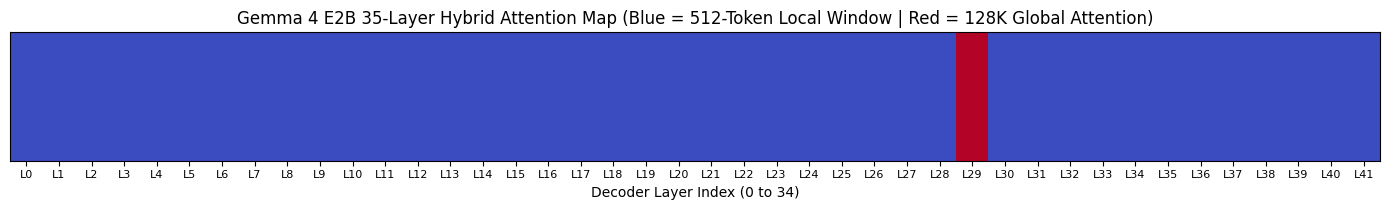

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Visualize the 35-layer Hybrid Attention Pattern (4 Local : 1 Global)
layers = model.model.language_model.layers
attn_types = []

for i, layer in enumerate(layers):
  # Check if the layer uses sliding window (local) or full (global) attention
  is_sliding = (
      getattr(layer.self_attn, "sliding_window", None) is not None
      or (i + 1) % 5 != 0
  )
  attn_types.append(0 if is_sliding else 1)

plt.figure(figsize=(14, 2.2))
plt.imshow([attn_types], cmap="coolwarm", aspect="auto")
plt.yticks([])
plt.xticks(range(len(layers)), [f"L{i}" for i in range(len(layers))], fontsize=8)
plt.title(
    "Gemma 4 E2B 35-Layer Hybrid Attention Map (Blue = 512-Token Local Window"
    " | Red = 128K Global Attention)"
)
plt.xlabel("Decoder Layer Index (0 to 34)")
plt.tight_layout()
plt.show()


# Gemma 4 — Architecture & Weights Inspector

**Run this after** the cell that creates `model` and `tokenizer`
(`attn_implementation="eager"` is required for the attention section).

| Cell | Question it answers |
|---|---|
| 1 | Setup and helpers |
| 2 | What does the config say? (layers, heads, sliding vs global attention, PLE) |
| 3 | What does the module tree look like? |
| 4 | Where do the parameters and bytes live? (category, dtype, device) |
| 5 | Are all decoder layers identical? |
| 6 | How much memory do the weights really take per GPU? |
| 7 | What are the weight statistics, tensor by tensor? (scale, zeros, NaN/Inf, fp16 risk) |
| 8 | How "rich" are the weight matrices? (SVD, effective rank) |
| 9 | What does one forward pass do to the hidden states, layer by layer? |
| 10 | What do the attention heads do? (entropy, sink, previous-token heads) |
| 11 | What would the model predict if it stopped after layer *i*? (logit lens) |

In [10]:
# CELL 1 - Setup & helpers (assumes `model` and `tokenizer` already exist)
import re, math, json, collections
import numpy as np
import torch
import torch.nn.functional as F
import pandas as pd
try:
    from IPython.display import display
except ImportError:                       # plain-Python fallback
    display = print

pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4g}")

tokenizer = globals().get("tokenizer", globals().get("tok"))
assert "model" in globals() and tokenizer is not None, "Load `model` and `tokenizer` first."
model.eval()

GB = 1024 ** 3
FP16_MAX = 65504.0                                   # largest finite float16 value
NON_TEXT = re.compile(r"vision|audio", re.I)         # image/audio towers of a multimodal model
LAYER_RE = re.compile(r"(?:^|\.)layers\.(\d+)\.")    # '...layers.<i>....' inside a parameter name

CATS = [   # first match wins
    ("vision tower",         r"vision"),
    ("audio tower",          r"audio"),
    ("per-layer emb (PLE)",  r"per_layer"),
    ("token emb / lm_head",  r"embed_tokens|word_embeddings|lm_head"),
    ("norms",                r"norm"),
    ("attention",            r"self_attn|attention|q_proj|k_proj|v_proj|o_proj"),
    ("mlp",                  r"mlp|gate_proj|up_proj|down_proj|experts|router"),
]
def categorize(name):
    for label, pat in CATS:
        if re.search(pat, name, re.I):
            return label
    return "other"

print(f"torch {torch.__version__} | model class: {type(model).__name__} | device: {model.device}")

torch 2.11.0+cu130 | model class: Gemma4ForConditionalGeneration | device: cuda:0


## 2. Configuration
A multimodal model has a *composite* config. `get_text_config()` returns the text decoder part.
**Sliding-window attention** (each token sees only the last N tokens) is cheap;
**global attention** (each token sees everything before it) is expensive.
Gemma mixes both, and `layer_types` tells you which layer is which.

In [11]:
# CELL 2 - Configuration: what the architecture says about itself
cfg_full = model.config
cfg = getattr(cfg_full, "get_text_config", lambda: cfg_full)()
print(f"model class : {type(model).__name__}")
print(f"config class: {type(cfg_full).__name__}  ->  text config: {type(cfg).__name__}")
print("sub-configs :", list(getattr(cfg_full, "sub_configs", {}).keys()) or "none")

FIELDS = ["num_hidden_layers", "hidden_size", "intermediate_size", "num_attention_heads",
          "num_key_value_heads", "head_dim", "global_head_dim", "num_global_key_value_heads",
          "vocab_size", "vocab_size_per_layer_input", "hidden_size_per_layer_input",
          "num_kv_shared_layers", "sliding_window", "max_position_embeddings",
          "hidden_activation", "rms_norm_eps", "tie_word_embeddings",
          "final_logit_softcapping", "use_bidirectional_attention", "rope_parameters"]
def read_field(c, name):
    # Newer transformers marks some Gemma 4 fields (e.g. head_dim) as PER-LAYER: plain c.head_dim then raises
    # AmbiguousGlobalPerLayerAttributeError. In that case we ask every layer and summarise the distinct values.
    try:
        return str(getattr(c, name))
    except AttributeError:
        return "n/a"
    except Exception:
        vals = collections.Counter(str(getattr(c.per_layer_config[i], name, "n/a"))
                                   for i in range(c.num_hidden_layers))
        return " | ".join(f"{v}  (x{n} layers)" for v, n in vals.items())

display(pd.DataFrame([(f, read_field(cfg, f)) for f in FIELDS], columns=["field", "value"]))

if getattr(cfg, "is_heterogeneous", False):      # layers are NOT all configured the same way
    per = [cfg.per_layer_config[i].to_dict() for i in range(cfg.num_hidden_layers)]
    varying = [k for k in per[0] if k != "per_layer_config" and len({str(d.get(k)) for d in per}) > 1]
    print("\nHETEROGENEOUS config - attributes that differ between layers:", varying)
    display(pd.DataFrame([{"layer": i, **{k: str(d.get(k)) for k in varying}} for i, d in enumerate(per)]))

layer_types = getattr(cfg, "layer_types", None)
if layer_types:
    print("\nlayer_types:", dict(collections.Counter(layer_types)))
    print("pattern    :", "".join("S" if t.startswith("sliding") else "G" for t in layer_types),
          "  (S = sliding-window, G = global/full attention)")

print("\n--- full text config (first 2500 chars) ---")
print(json.dumps(cfg.to_dict(), indent=1, default=str)[:2500])

model class : Gemma4ForConditionalGeneration
config class: Gemma4Config  ->  text config: Gemma4TextConfig
sub-configs : ['text_config', 'vision_config', 'audio_config']


,field,value
0,num_hidden_layers,42
1,hidden_size,2560
2,intermediate_size,10240
3,num_attention_heads,8
4,num_key_value_heads,2
5,head_dim,256 (x35 layers) | 512 (x7 layers)
6,global_head_dim,n/a
7,num_global_key_value_heads,n/a
8,vocab_size,262144
9,vocab_size_per_layer_input,262144



HETEROGENEOUS config - attributes that differ between layers: ['head_dim']


,layer,head_dim
0,0,256
1,1,256
2,2,256
3,3,256
4,4,256
5,5,512
6,6,256
7,7,256
8,8,256
9,9,256



layer_types: {'sliding_attention': 35, 'full_attention': 7}
pattern    : SSSSSGSSSSSGSSSSSGSSSSSGSSSSSGSSSSSGSSSSSG   (S = sliding-window, G = global/full attention)

--- full text config (first 2500 chars) ---
{
 "transformers_version": "5.20.2",
 "architectures": null,
 "output_hidden_states": false,
 "return_dict": true,
 "dtype": "float16",
 "chunk_size_feed_forward": 0,
 "is_encoder_decoder": false,
 "id2label": {
  "0": "LABEL_0",
  "1": "LABEL_1"
 },
 "label2id": {
  "LABEL_0": 0,
  "LABEL_1": 1
 },
 "problem_type": null,
 "vocab_size": 262144,
 "hidden_size": 2560,
 "intermediate_size": 10240,
 "num_hidden_layers": 42,
 "num_attention_heads": 8,
 "num_key_value_heads": 2,
 "head_dim": 256,
 "hidden_activation": "gelu_pytorch_tanh",
 "max_position_embeddings": 131072,
 "initializer_range": 0.02,
 "rms_norm_eps": 1e-06,
 "use_cache": true,
 "pad_token_id": 0,
 "eos_token_id": 1,
 "bos_token_id": 2,
 "tie_word_embeddings": true,
 "rope_parameters": {
  "full_attention": {
   "par

In [12]:
# CELL 3 - Module tree with parameter counts (numbered blocks are collapsed to the first one)
def n_params(m):
    return sum(p.numel() for p in m.parameters())
TOTAL = n_params(model)            # tied weights are counted once

def print_tree(module, name="model", depth=0, max_depth=4):
    n = n_params(module)
    print(f"{'    ' * depth}{name}  [{type(module).__name__}]  {n / 1e6:,.1f}M  ({100 * n / TOTAL:.1f}%)")
    if depth >= max_depth:
        return
    kids = list(module.named_children())
    numbered = [k for k in kids if k[0].isdigit()]
    if len(numbered) > 2:          # e.g. a ModuleList of decoder layers: show index 0 only
        shown = [k for k in kids if not k[0].isdigit()] + numbered[:1]
        for cname, child in shown:
            print_tree(child, cname, depth + 1, max_depth)
        print(f"{'    ' * (depth + 1)}... {len(numbered) - 1} more blocks (indices 1..{numbered[-1][0]}); "
              f"CELL 5 shows how they differ")
    else:
        for cname, child in kids:
            print_tree(child, cname, depth + 1, max_depth)

print_tree(model, max_depth=4)     # raise max_depth to 5-6 to see inside attention and MLP

model  [Gemma4ForConditionalGeneration]  7,941.1M  (100.0%)
    model  [Gemma4Model]  7,941.1M  (100.0%)
        vision_tower  [Gemma4VisionModel]  167.4M  (2.1%)
            patch_embedder  [Gemma4VisionPatchEmbedder]  16.3M  (0.2%)
                input_proj  [Linear]  0.6M  (0.0%)
            encoder  [Gemma4VisionEncoder]  151.0M  (1.9%)
                rotary_emb  [Gemma4VisionRotaryEmbedding]  0.0M  (0.0%)
                layers  [ModuleList]  151.0M  (1.9%)
            pooler  [Gemma4VisionPooler]  0.0M  (0.0%)
        language_model  [Gemma4TextModel]  7,463.0M  (94.0%)
            embed_tokens  [Gemma4TextScaledWordEmbedding]  671.1M  (8.5%)
            layers  [ModuleList]  3,945.8M  (49.7%)
                0  [Gemma4TextDecoderLayer]  93.1M  (1.2%)
                ... 41 more blocks (indices 1..41); CELL 5 shows how they differ
            norm  [Gemma4RMSNorm]  0.0M  (0.0%)
            rotary_emb  [Gemma4TextRotaryEmbedding]  0.0M  (0.0%)
            embed_tokens_per_layer 

## 4. Where do the parameters live?
Gemma 4 "E" models use **Per-Layer Embeddings (PLE)**: large lookup tables that add little compute but a lot of
memory. That is why "effective 4B" and "total ~8B" differ. The category table below measures it directly.

In [13]:
# CELL 4 - Parameters and bytes by category, dtype and device
cat = collections.defaultdict(lambda: [0, 0])
dt  = collections.defaultdict(lambda: [0, 0])
dev = collections.defaultdict(lambda: [0, 0])
other_names = []
for name, p in model.named_parameters():
    c = categorize(name)
    for table, key in ((cat, c), (dt, str(p.dtype).replace("torch.", "")), (dev, str(p.device))):
        table[key][0] += p.numel()
        table[key][1] += p.numel() * p.element_size()
    if c == "other":
        other_names.append(name)

def to_df(table, label):
    df = pd.DataFrame([(k, v[0] / 1e6, 100 * v[0] / TOTAL, v[1] / GB) for k, v in table.items()],
                      columns=[label, "params_M", "share_%", "size_GB"])
    return df.sort_values("params_M", ascending=False).reset_index(drop=True)

print(f"TOTAL parameters: {TOTAL:,}  (~{TOTAL / 1e9:.2f}B)")
display(to_df(cat, "category")); display(to_df(dt, "dtype")); display(to_df(dev, "device"))

core = TOTAL - cat["per-layer emb (PLE)"][0] - cat["vision tower"][0] - cat["audio tower"][0]
print(f"\nText decoder excluding PLE / vision / audio: {core / 1e9:.2f}B parameters "
      f"(includes token embeddings; Google's '4B effective' headline uses its own definition)")
buf = sum(b.numel() * b.element_size() for b in model.buffers())
print(f"Buffers (non-trainable tensors such as RoPE tables): {buf / GB:.3f} GB")
if other_names:
    print("Uncategorised names (extend CATS if they matter):", other_names[:15])

TOTAL parameters: 7,941,100,832  (~7.94B)


,category,params_M,share_%,size_GB
0,mlp,"3,303",41.59,6.152
1,per-layer emb (PLE),"2,901",36.53,5.404
2,token emb / lm_head,671.1,8.451,1.25
3,attention,587.2,7.394,1.094
4,audio tower,308.8,3.888,0.5751
5,vision tower,169.3,2.132,0.3154
6,norms,0.4524,0.005696,0.0008426


,dtype,params_M,share_%,size_GB
0,float16,"7,941",100,14.79


,device,params_M,share_%,size_GB
0,cuda:0,"4,593",57.84,8.555
1,cuda:1,"3,348",42.16,6.237



Text decoder excluding PLE / vision / audio: 4.56B parameters (includes token embeddings; Google's '4B effective' headline uses its own definition)
Buffers (non-trainable tensors such as RoPE tables): 0.000 GB


In [14]:
# CELL 5 - Per-layer anatomy: are all decoder layers identical?
per_layer = collections.defaultdict(collections.Counter)
for name, p in model.named_parameters():
    if NON_TEXT.search(name):
        continue
    m = LAYER_RE.search(name)
    if m:
        per_layer[int(m.group(1))][categorize(name)] += p.numel()

rows = []
for i in sorted(per_layer):
    c = per_layer[i]
    rows.append(dict(layer=i,
                     type=(layer_types[i] if layer_types and i < len(layer_types) else "?"),
                     attn_M=c["attention"] / 1e6, mlp_M=c["mlp"] / 1e6, norms_K=c["norms"] / 1e3,
                     ple_M=c["per-layer emb (PLE)"] / 1e6, total_M=sum(c.values()) / 1e6))
df_layers = pd.DataFrame(rows)
if df_layers.empty:
    print("No 'layers.<i>.' parameter names found. Inspect them with: [n for n, _ in model.named_parameters()][:20]")
else:
    display(df_layers)
    sig = df_layers.round({"attn_M": 3, "mlp_M": 3}).groupby(["type", "attn_M", "mlp_M"]).size().rename("n_layers")
    print("\nDistinct layer designs (attention type, attention size, MLP size):")
    display(sig.reset_index())

,layer,type,attn_M,mlp_M,norms_K,ple_M,total_M
0,0,sliding_attention,13.11,78.64,10.75,1.313,93.07
1,1,sliding_attention,13.11,78.64,10.75,1.313,93.07
2,2,sliding_attention,13.11,78.64,10.75,1.313,93.07
3,3,sliding_attention,13.11,78.64,10.75,1.313,93.07
4,4,sliding_attention,13.11,78.64,10.75,1.313,93.07
5,5,full_attention,26.21,78.64,11.26,1.313,106.2
6,6,sliding_attention,13.11,78.64,10.75,1.313,93.07
7,7,sliding_attention,13.11,78.64,10.75,1.313,93.07
8,8,sliding_attention,13.11,78.64,10.75,1.313,93.07
9,9,sliding_attention,13.11,78.64,10.75,1.313,93.07



Distinct layer designs (attention type, attention size, MLP size):


,type,attn_M,mlp_M,n_layers
0,full_attention,20.97,78.64,3
1,full_attention,26.21,78.64,4
2,sliding_attention,10.49,78.64,15
3,sliding_attention,13.11,78.64,20


In [15]:
# CELL 6 - Memory: weights vs the GPU you actually have
print(f"get_memory_footprint() (params + buffers): {model.get_memory_footprint() / GB:.2f} GB")
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        pr = torch.cuda.get_device_properties(i)
        print(f"GPU{i} {pr.name}: allocated {torch.cuda.memory_allocated(i) / GB:.2f} GB | "
              f"reserved {torch.cuda.memory_reserved(i) / GB:.2f} GB | total {pr.total_memory / GB:.2f} GB")
else:
    print("No CUDA device visible - model is on CPU.")
hf_map = getattr(model, "hf_device_map", None)
if hf_map:
    print("\ndevice_map summary (modules per device):", dict(collections.Counter(str(v) for v in hf_map.values())))
    if any(str(v) in ("cpu", "disk") for v in hf_map.values()):
        print("WARNING: some modules are offloaded to CPU/disk -> everything below will be slower.")

get_memory_footprint() (params + buffers): 14.79 GB
GPU0 Tesla T4: allocated 8.56 GB | reserved 8.56 GB | total 14.56 GB
GPU1 Tesla T4: allocated 6.24 GB | reserved 6.24 GB | total 14.56 GB

device_map summary (modules per device): {'0': 43, '1': 10}


## 7. Weight statistics
Exact statistics for **every** tensor, computed in chunks so the huge embedding tables cannot run the GPU out of memory.
`absmax` is compared with the largest float16 number (65,504). `zeros_pct` shows dead or sparse weights.

In [16]:
# CELL 7 - Exact weight statistics for every tensor
import time
@torch.no_grad()
def tensor_stats(p, chunk=8_000_000):
    flat = p.detach().reshape(-1)
    n = flat.numel()
    s = s2 = 0.0
    mn, mx = float("inf"), float("-inf")
    zeros = bad = 0
    for i in range(0, n, chunk):
        x = flat[i:i + chunk].float()
        bad   += (~torch.isfinite(x)).sum().item()
        zeros += (x == 0).sum().item()
        s     += x.sum(dtype=torch.float64).item()
        s2    += (x * x).sum(dtype=torch.float64).item()
        mn = min(mn, x.min().item()); mx = max(mx, x.max().item())
    mean = s / n
    return dict(n_M=n / 1e6, mean=mean, std=math.sqrt(max(s2 / n - mean ** 2, 0.0)), rms=math.sqrt(s2 / n),
                absmax=max(abs(mn), abs(mx)), zeros_pct=100 * zeros / n, nonfinite=bad)

t0, rows = time.time(), []
for k, (name, p) in enumerate(model.named_parameters(), 1):
    m = LAYER_RE.search(name)
    rows.append(dict(name=name, category=categorize(name),
                     layer=int(m.group(1)) if (m and not NON_TEXT.search(name)) else -1,
                     shape=tuple(p.shape), dtype=str(p.dtype).replace("torch.", ""), **tensor_stats(p)))
    if k % 100 == 0:
        print(f"  scanned {k} tensors ({time.time() - t0:.0f}s)")
df_w = pd.DataFrame(rows)

print(f"\nscanned {len(df_w)} tensors in {time.time() - t0:.0f}s | non-finite values: {int(df_w.nonfinite.sum())} | "
      f"largest |w|: {df_w.absmax.max():.4g}  (fp16 max = {FP16_MAX:,.0f})")
display(df_w.groupby("category").agg(tensors=("name", "count"), params_M=("n_M", "sum"),
                                     median_std=("std", "median"), max_absmax=("absmax", "max"),
                                     mean_zeros_pct=("zeros_pct", "mean")))
print("\nTop 10 weight MATRICES (2-D) by largest |weight|:")
mats = df_w[df_w["shape"].map(len) == 2]
display(mats.sort_values("absmax", ascending=False).head(10)[["name", "shape", "dtype", "std", "absmax"]])
print("\nTop 5 norm / 1-D tensors by largest |weight|:")
vecs = df_w[df_w["shape"].map(len) == 1]
display(vecs.sort_values("absmax", ascending=False).head(5)[["name", "shape", "dtype", "std", "absmax"]])
print("\nWeight scale (median std) by layer and category:")
display(df_w[df_w.layer >= 0].pivot_table(index="layer", columns="category", values="std", aggfunc="median"))

  scanned 100 tensors (0s)
  scanned 200 tensors (0s)
  scanned 300 tensors (1s)
  scanned 400 tensors (1s)
  scanned 500 tensors (2s)
  scanned 600 tensors (2s)
  scanned 700 tensors (2s)
  scanned 800 tensors (3s)
  scanned 900 tensors (5s)
  scanned 1000 tensors (5s)
  scanned 1100 tensors (5s)

scanned 1106 tensors in 5s | non-finite values: 0 | largest |w|: 450  (fp16 max = 65,504)


,tensors,params_M,median_std,max_absmax,mean_zeros_pct
category,,,,,
attention,132,587.2,0.02014,0.2314,0.0001458
audio tower,272,308.8,0.1137,106,16.94
mlp,126,"3,303",0.01944,0.207,0.0001794
norms,235,0.4524,0.3724,450,0
per-layer emb (PLE),129,"2,901",0.0625,11.44,0.005408
token emb / lm_head,1,671.1,0.01976,0.5547,0.0001188
vision tower,211,169.3,0.03609,71.5,1.411



Top 10 weight MATRICES (2-D) by largest |weight|:


,name,shape,dtype,std,absmax
830,model.language_model.embed_tokens_per_layer.we...,"(262144, 10752)",float16,0.0625,0.9609
145,model.vision_tower.encoder.layers.11.self_attn...,"(768, 768)",float16,0.03608,0.707
736,model.language_model.layers.34.per_layer_proje...,"(2560, 256)",float16,0.06524,0.6523
337,model.language_model.layers.7.per_layer_projec...,"(2560, 256)",float16,0.06541,0.6523
710,model.language_model.layers.32.per_layer_proje...,"(2560, 256)",float16,0.06536,0.6523
671,model.language_model.layers.29.per_layer_proje...,"(2560, 256)",float16,0.06483,0.6484
401,model.language_model.layers.11.per_layer_proje...,"(2560, 256)",float16,0.06503,0.6484
225,model.language_model.layers.0.per_layer_projec...,"(2560, 256)",float16,0.0649,0.6484
433,model.language_model.layers.13.per_layer_proje...,"(2560, 256)",float16,0.06497,0.6484
814,model.language_model.layers.40.per_layer_proje...,"(2560, 256)",float16,0.06427,0.6445



Top 5 norm / 1-D tensors by largest |weight|:


,name,shape,dtype,std,absmax
302,model.language_model.layers.5.pre_feedforward_...,"(2560,)",float16,109.1,450
396,model.language_model.layers.11.input_layernorm...,"(2560,)",float16,40.14,374
414,model.language_model.layers.12.pre_feedforward...,"(2560,)",float16,35.51,364
318,model.language_model.layers.6.pre_feedforward_...,"(2560,)",float16,82.51,350
348,model.language_model.layers.8.input_layernorm....,"(2560,)",float16,64.1,316



Weight scale (median std) by layer and category:


category,attention,mlp,norms,per-layer emb (PLE)
layer,,,,
0,0.02019,0.01944,3.303,0.0649
1,0.02033,0.01939,2.522,0.06281
2,0.01878,0.02042,0.4587,0.0637
3,0.02039,0.01935,0.6497,0.06396
4,0.01966,0.0202,0.7897,0.06276
5,0.01985,0.01949,0.8638,0.02596
6,0.01992,0.0204,1.072,0.06097
7,0.02056,0.0204,0.709,0.06541
8,0.02039,0.02036,1.72,0.05967


## 8. Spectral view (SVD)
Every weight matrix W can be split into directions of different strength (singular values).
* **Stable rank** = ||W||_F^2 / sigma_max^2 (how many directions carry the energy).
* **Effective rank** = exp(entropy of sigma / sum(sigma)) (Roy & Vetterli, 2007): a smooth count of "active" directions.

The SVD runs on the CPU, so it cannot cause a GPU out-of-memory error.

In [17]:
# CELL 8 - Effective rank of a few weight matrices (extend SVD_SUFFIXES for more, each SVD takes seconds-minutes)
SVD_SUFFIXES = ("q_proj", "down_proj")

def find_weight(layer, suffix):
    pat = re.compile(rf"(?:^|\.)layers\.{layer}\.(?:\w+\.)*{suffix}\.weight$")
    for name, p in model.named_parameters():
        if not NON_TEXT.search(name) and pat.search(name):
            return name, p
    return None, None

@torch.no_grad()
def spectrum(W):
    s = torch.linalg.svdvals(W.detach().float().cpu())
    p = s / s.sum()
    erank = torch.exp(-(p * torch.log(p.clamp_min(1e-30))).sum()).item()
    return dict(shape=tuple(W.shape), sigma_max=s[0].item(), sigma_min=s[-1].item(),
                stable_rank=((s ** 2).sum() / s[0] ** 2).item(), effective_rank=erank,
                eff_rank_pct=100 * erank / len(s), top1_energy_pct=100 * (s[0] ** 2 / (s ** 2).sum()).item())

L = cfg.num_hidden_layers
t0, rows = time.time(), []
for layer in sorted({0, L // 2, L - 1}):
    for suffix in SVD_SUFFIXES:
        name, W = find_weight(layer, suffix)
        if W is not None:
            rows.append(dict(name=name, **spectrum(W)))
print(f"SVD of {len(rows)} matrices took {time.time() - t0:.0f}s")
display(pd.DataFrame(rows))

SVD of 6 matrices took 17s


,name,shape,sigma_max,sigma_min,stable_rank,effective_rank,eff_rank_pct,top1_energy_pct
0,model.language_model.layers.0.self_attn.q_proj...,"(2048, 2560)",4.838,0.04584,91.34,"1,684",82.23,1.095
1,model.language_model.layers.0.mlp.down_proj.we...,"(2560, 10240)",3.708,0.4058,195.3,"2,452",95.78,0.5121
2,model.language_model.layers.21.self_attn.q_pro...,"(2048, 2560)",4.521,0.02355,90.66,"1,337",65.28,1.103
3,model.language_model.layers.21.mlp.down_proj.w...,"(2560, 10240)",4.002,0.1439,162.2,"2,349",91.76,0.6167
4,model.language_model.layers.41.self_attn.q_pro...,"(4096, 2560)",6.572,0.03465,87.92,"1,702",66.47,1.137
5,model.language_model.layers.41.mlp.down_proj.w...,"(2560, 10240)",4.401,0.2894,124.9,"2,398",93.68,0.8007


## 9. One forward pass, everything captured
Things to look for in the table:
* `bos_norm` far larger than `rest_norm` = **massive activations** on the first token (Sun et al., 2024).
* `fp16_headroom_x` below about 10 = activations are close to float16 overflow (a risk on T4 GPUs).
* `cos_prev` near 1 / small `update_ratio` = that layer changes the residual stream very little.

In Hugging Face the last hidden state is normally *after* the final norm.

In [18]:
# CELL 9 - Forward pass and hidden-state anatomy
SAMPLE = "The company reported a massive 25% increase in quarterly revenue."
enc = tokenizer(SAMPLE, return_tensors="pt")
inputs = {k: v.to(model.device) for k, v in enc.items() if k in ("input_ids", "attention_mask")}
ids = inputs["input_ids"][0].tolist()
tokens = tokenizer.convert_ids_to_tokens(ids)
print(f"{len(ids)} tokens:", list(zip(range(len(ids)), tokens)))

with torch.no_grad():
    out = model(**inputs, output_hidden_states=True, output_attentions=True, use_cache=False)

att = out.attentions
print("\n=== TENSOR SHAPES ===")
print("input_ids     :", tuple(inputs["input_ids"].shape))
print("hidden_states :", len(out.hidden_states), "x", tuple(out.hidden_states[-1].shape), "(embeddings + one per layer)")
if att and att[0] is not None:
    print("attentions    :", len(att), "layers, first layer", tuple(att[0].shape), "= (batch, heads, query, key)")
else:
    print("attentions    : None -> load the model with attn_implementation='eager'")
print("logits        :", tuple(out.logits.shape))

rows, prev = [], None
for i, h in enumerate(out.hidden_states):
    h = h[0].float()                                         # [tokens, hidden]
    nrm = h.norm(dim=-1)
    r = dict(idx=i, state="embeddings" if i == 0 else f"after layer {i - 1}",
             mean_norm=nrm.mean().item(), bos_norm=nrm[0].item(),
             rest_norm=nrm[1:].mean().item() if len(nrm) > 1 else float("nan"),
             absmax=h.abs().max().item())
    r["fp16_headroom_x"] = FP16_MAX / r["absmax"] if r["absmax"] else float("inf")
    if prev is not None:
        r["cos_prev"] = F.cosine_similarity(h, prev, dim=-1).mean().item()
        r["update_ratio"] = ((h - prev).norm(dim=-1) / prev.norm(dim=-1).clamp_min(1e-6)).mean().item()
    prev = h
    rows.append(r)
df_h = pd.DataFrame(rows)
display(df_h)
print(f"Smallest fp16 headroom: {df_h.fp16_headroom_x.min():.3g}x at '{df_h.loc[df_h.fp16_headroom_x.idxmin(), 'state']}'; "
      f"all logits finite: {bool(torch.isfinite(out.logits).all())}")

14 tokens: [(0, 'The'), (1, '▁company'), (2, '▁reported'), (3, '▁a'), (4, '▁massive'), (5, '▁'), (6, '2'), (7, '5'), (8, '%'), (9, '▁increase'), (10, '▁in'), (11, '▁quarterly'), (12, '▁revenue'), (13, '.')]

=== TENSOR SHAPES ===
input_ids     : (1, 14)
hidden_states : 43 x (1, 14, 2560) (embeddings + one per layer)
attentions    : 42 layers, first layer (1, 8, 14, 14) = (batch, heads, query, key)
logits        : (1, 14, 262144)


,idx,state,mean_norm,bos_norm,rest_norm,absmax,fp16_headroom_x,cos_prev,update_ratio
0,0,embeddings,50.6,50.6,50.6,4.473,1.465e+04,NaN,NaN
1,1,after layer 0,53.12,48.31,53.48,17.92,"3,655",0.03374,1.425
2,2,after layer 1,88.17,86.56,88.29,60.78,"1,078",0.2878,1.676
3,3,after layer 2,94.79,96.82,94.64,69.5,942.5,0.91,0.4467
4,4,after layer 3,98.62,102.5,98.32,76.56,855.6,0.8873,0.4856
5,5,after layer 4,98.05,97.14,98.12,60.84,"1,077",0.7036,0.7689
6,6,after layer 5,84.59,87.05,84.4,42,"1,560",0.7751,0.6397
7,7,after layer 6,85.42,85.22,85.44,31.52,"2,078",0.6589,0.8316
8,8,after layer 7,77.06,76.47,77.1,28.23,"2,320",0.8029,0.6036
9,9,after layer 8,45.14,46.46,45.04,8.078,"8,109",0.4388,0.9113


Smallest fp16 headroom: 856x at 'after layer 3'; all logits finite: True


## 10. Attention anatomy
Per layer (averaged over heads unless noted):
* `norm_entropy`: 0 = each token attends to one place, 1 = spread evenly.
* `sink_on_BOS`: attention mass on the first token, the **attention sink** (Xiao et al., 2023).
* `prev_tok_best`: the strongest "previous-token" head, and which head it is.
* `rowsum_err`: sanity check, attention rows must sum to 1 (about 1e-3 is normal in fp16).

With only ~14 tokens the sliding window is never reached, so sliding and global layers look alike.
Try a longer text to see them diverge.

,layer,type,heads,rowsum_err,self_mass,mean_distance,norm_entropy,sink_on_BOS,prev_tok_best,prev_tok_head
0,0,sliding_attention,8,0.0003123,0.2157,2.548,0.6272,0.1614,0.6578,3
1,1,sliding_attention,8,0.0002527,0.1767,2.213,0.6202,0.07537,0.7194,5
2,2,sliding_attention,8,0.0003519,0.4811,1.622,0.5493,0.03803,0.4366,1
3,3,sliding_attention,8,0.0002747,0.2514,2.577,0.6835,0.08836,0.4088,2
4,4,sliding_attention,8,0.0002441,0.4156,1.832,0.609,0.1105,0.5739,2
5,5,full_attention,8,0.0002446,0.754,0.5684,0.3491,0.0421,0.2712,6
6,6,sliding_attention,8,0.0002441,0.4443,1.896,0.6225,0.1048,0.2382,7
7,7,sliding_attention,8,0.0003119,0.3163,2.176,0.6644,0.1851,0.4815,5
8,8,sliding_attention,8,0.0002689,0.2309,2.437,0.7408,0.129,0.3523,5
9,9,sliding_attention,8,0.000325,0.2513,2.369,0.5899,0.1484,0.402,3


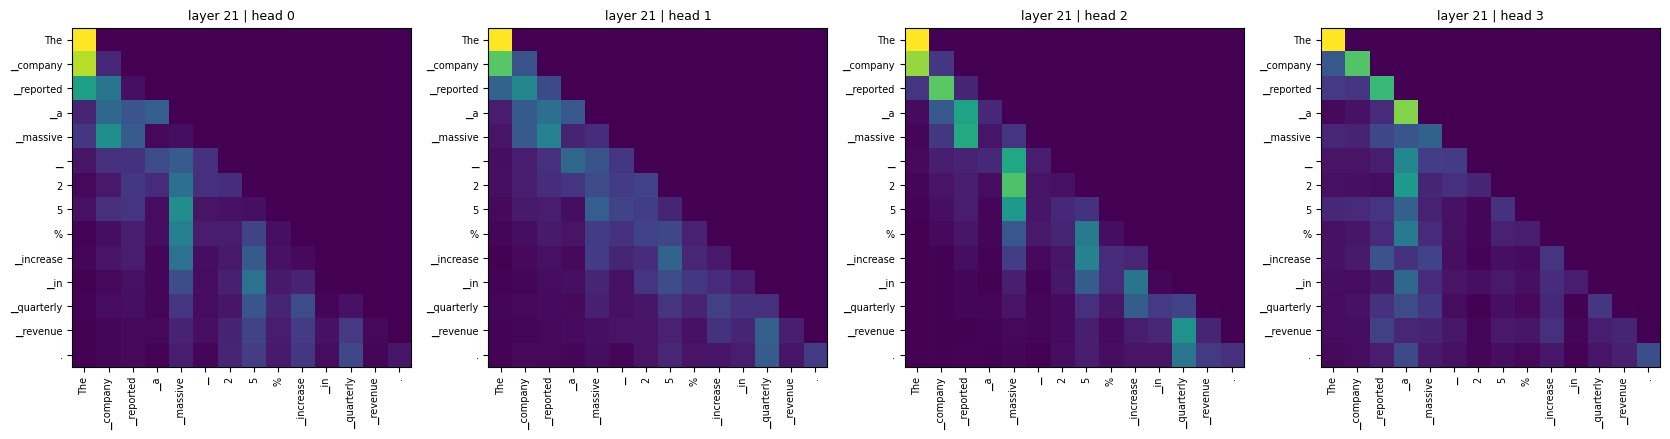

In [19]:
# CELL 10 - Attention anatomy per layer
import matplotlib.pyplot as plt

def attention_table(att):
    rows = []
    for li, a in enumerate(att):
        if a is None:
            rows.append(dict(layer=li, note="no attention returned"))
            continue
        A = a[0].float()                                        # [heads, q, k]
        H, Tq, Tk = A.shape
        q = torch.arange(Tq, device=A.device); k = torch.arange(Tk, device=A.device)
        ent = -(A.clamp_min(1e-12).log() * A).sum(-1)           # [H, Tq] entropy in nats
        max_ent = torch.log((q + 1).float()).clamp_min(1e-9)    # causal: query t sees t+1 keys
        dist = (q[:, None] - k[None, :]).abs().float()
        row = dict(layer=li, type=(layer_types[li] if layer_types and li < len(layer_types) else "?"), heads=H,
                   rowsum_err=(A.sum(-1) - 1).abs().max().item(),
                   self_mass=A[:, q, q].mean().item() if Tq == Tk else float("nan"),
                   mean_distance=(A * dist).sum(-1).mean().item())
        if Tq > 1 and Tq == Tk:
            pm = A[:, q[1:], q[1:] - 1].mean(-1)                # [H] previous-token mass per head
            row.update(norm_entropy=(ent[:, 1:] / max_ent[1:]).mean().item(),
                       sink_on_BOS=A[:, 1:, 0].mean().item(),
                       prev_tok_best=pm.max().item(), prev_tok_head=int(pm.argmax()))
        rows.append(row)
    return pd.DataFrame(rows)

if att and att[0] is not None:
    df_a = attention_table(att)
    display(df_a)
    def plot_attention(layer, heads=(0, 1, 2, 3)):
        A = att[layer][0].float().cpu()
        heads = [h for h in heads if h < A.shape[0]]
        fig, axes = plt.subplots(1, len(heads), figsize=(4.2 * len(heads), 4.2), squeeze=False)
        for ax, h in zip(axes[0], heads):
            ax.imshow(A[h].numpy(), cmap="viridis")
            ax.set_title(f"layer {layer} | head {h}", fontsize=9)
            ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, rotation=90, fontsize=7)
            ax.set_yticks(range(len(tokens))); ax.set_yticklabels(tokens, fontsize=7)
        plt.tight_layout(); plt.show()
    plot_attention(L // 2)          # try plot_attention(0), plot_attention(L - 1, heads=(0, 1))
else:
    print("No attention tensors captured - reload the model with attn_implementation='eager'.")

## 11. Logit lens
Feed the hidden state after layer *i* straight into the final norm and output head to see what the model "thinks"
the next token is at that depth (nostalgebraist, 2020; refined as the *tuned lens* by Belrose et al., 2023).
It is a rough tool: early layers often give gibberish.

In [20]:
# CELL 11 - Logit lens on the final position
def find_final_norm(m):
    c = [(n, mod) for n, mod in m.named_modules()
         if n.split(".")[-1] == "norm" and not re.search(r"layers\.\d+|vision|audio", n)]
    return c[-1] if c else (None, None)

try:
    norm_name, final_norm = find_final_norm(model)
    head = model.get_output_embeddings()
    softcap = getattr(cfg, "final_logit_softcapping", None)
    print("final norm:", norm_name, "| output head:", type(head).__name__, "| softcap:", softcap)

    @torch.no_grad()
    def lens_logits(h_vec, apply_norm=True):
        x = h_vec.unsqueeze(0)
        if apply_norm and final_norm is not None:
            pn = next(final_norm.parameters(), None)
            x = final_norm(x.to(pn.device) if pn is not None else x)
        x = x.to(head.weight.device, head.weight.dtype)
        lg = head(x).float()[0]
        return torch.tanh(lg / softcap) * softcap if softcap else lg

    last = len(out.hidden_states) - 1
    ref = out.logits[0, -1].float()
    chk = lens_logits(out.hidden_states[last][0, -1], apply_norm=False).to(ref.device)
    LAST_IS_NORMED = chk.argmax().item() == ref.argmax().item()
    print(f"sanity: last hidden state without extra norm reproduces real logits? {LAST_IS_NORMED} "
          f"(max |diff| = {(chk - ref).abs().max().item():.3g})")

    final_top = ref.argmax().item()
    rows = []
    for i, h in enumerate(out.hidden_states):
        lg = lens_logits(h[0, -1], apply_norm=not (i == last and LAST_IS_NORMED))
        pr = torch.softmax(lg, -1)
        top = torch.topk(pr, 3)
        rows.append(dict(state=i, top1=repr(tokenizer.decode([top.indices[0].item()])), p1=top.values[0].item(),
                         top2=repr(tokenizer.decode([top.indices[1].item()])),
                         top3=repr(tokenizer.decode([top.indices[2].item()])),
                         rank_of_final_answer=int((lg > lg[final_top]).sum().item()) + 1,
                         p_final_answer=pr[final_top].item()))
    print("\nFinal answer of the full model:", repr(tokenizer.decode([final_top])))
    display(pd.DataFrame(rows))
except Exception as e:
    print("Logit lens skipped:", type(e).__name__, e)

final norm: model.language_model.norm | output head: Linear | softcap: 30.0
sanity: last hidden state without extra norm reproduces real logits? True (max |diff| = 0.0195)

Final answer of the full model: '<eos>'


,state,top1,p1,top2,top3,rank_of_final_answer,p_final_answer
0,0,'-',1.883e-05,"','",'.',190,1.882e-05
1,1,'펑',0.08475,'িলারা','следования',101744,2.227e-10
2,2,'excluded',0.03618,' misfort',' इंग',224114,2.373e-13
3,3,'尻',0.0339,'чис','朋',241813,4.96e-14
4,4,'垄',0.04142,'佩',' unsur',218054,3.282e-12
5,5,'ᡤ',0.0568,'膏',"""(':')[""",60656,1.655e-09
6,6,'祸',0.09672,'notes',' rede',58096,1.308e-09
7,7,'वाहा',0.05563,'localize','hare',46339,2.631e-08
8,8,'ümüzde',0.04045,'hare',' Kochubei',78422,3.678e-09
9,9,' Bishop',0.03263,' Peng',' Hur',6575,2.872e-06


## References
* Roy & Vetterli (2007), *The Effective Rank: A Measure of Effective Dimensionality* - https://infoscience.epfl.ch/record/110188/files/RoyV07.pdf
* Xiao et al. (2023), *Efficient Streaming Language Models with Attention Sinks* - https://arxiv.org/abs/2309.17453
* Sun et al. (2024), *Massive Activations in Large Language Models* - https://arxiv.org/abs/2402.17762
* Belrose et al. (2023), *Eliciting Latent Predictions from Transformers with the Tuned Lens* - https://arxiv.org/abs/2303.08112
* Hugging Face cache and model docs: https://huggingface.co/docs/transformers